# Pertemuan 10 — Tugas 1: Klasifikasi Suara Pria dan Wanita dengan kNN

Tugas ini membuat model kNN untuk mengklasifikasikan jenis suara `male` dan `female` pada dataset `voice.csv`. Berkas ini memuat 20 fitur akustik dari rekaman suara.

Tujuan tugas:
1. Membuat model klasifikasi kNN untuk label `male` dan `female`.
2. Melakukan percobaan untuk menemukan fitur yang paling optimal.
3. Menentukan nilai k terbaik berdasarkan fitur terpilih, disertai grafik analisis dan alasan.

Sumber: [Tugas 1](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi/tugas-1).

## 1. Import Library

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 2. Load Data dan Eksplorasi

Dataset dimuat dan dilakukan inspeksi awal: ukuran data, tipe kolom, nilai kosong, serta distribusi label.

In [2]:
df = pd.read_csv('voice.csv')
print('Ukuran data:', df.shape)
print('\nInfo data:')
df.info()
print('\nJumlah data per kelas:')
print(df['label'].value_counts())
print('\nNilai kosong:', df.isnull().sum().sum())

Ukuran data: (3168, 21)

Info data:
<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label

## 3. Encoding Label

Label `male` dan `female` diubah menjadi angka agar dapat diproses oleh model.

In [3]:
df['label'] = df['label'].map({'male': 1, 'female': 0})
print(df['label'].value_counts())
df.head()

label
1    1584
0    1584
Name: count, dtype: int64


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,1
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,1
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,1
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,1
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,1


## 4. Visualisasi Korelasi Fitur terhadap Label

Korelasi setiap fitur numerik terhadap label dihitung dan diurutkan untuk memperoleh gambaran awal fitur yang paling berpengaruh.

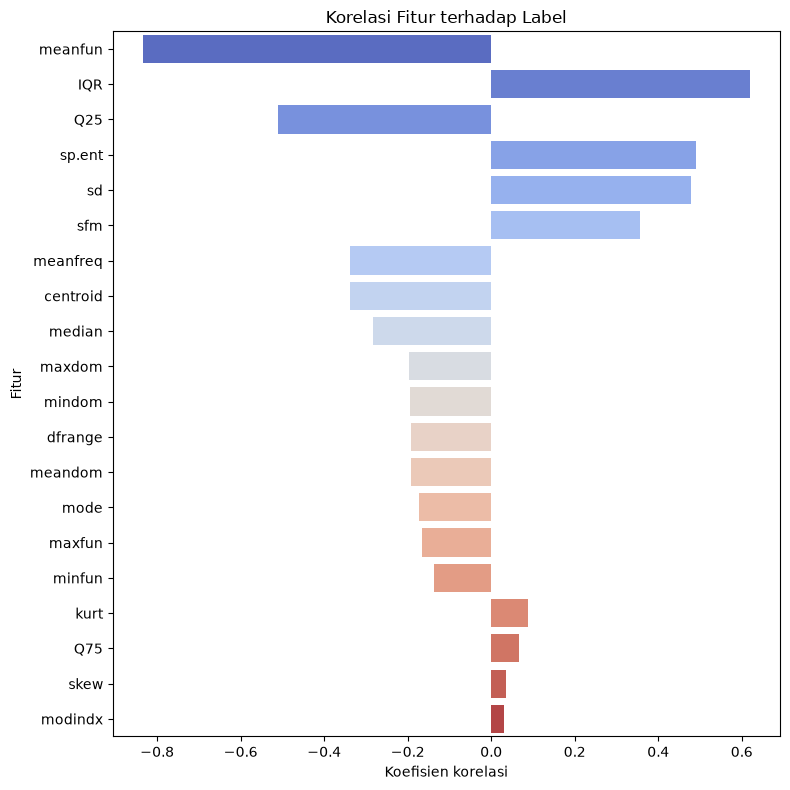

meanfun    -0.833921
IQR         0.618916
Q25        -0.511455
sp.ent      0.490552
sd          0.479539
sfm         0.357499
meanfreq   -0.337415
centroid   -0.337415
median     -0.283919
maxdom     -0.195657
mindom     -0.194974
dfrange    -0.192213
meandom    -0.191067
mode       -0.171775
maxfun     -0.166461
minfun     -0.136692
kurt        0.087195
Q75         0.066906
skew        0.036627
modindx     0.030801
Name: label, dtype: float64

In [4]:
korelasi = df.corr()['label'].drop('label').sort_values(key=abs, ascending=False)

plt.figure(figsize=(8, 8))
sns.barplot(x=korelasi.values, y=korelasi.index, hue=korelasi.index,
            palette='coolwarm', legend=False)
plt.title('Korelasi Fitur terhadap Label')
plt.xlabel('Koefisien korelasi')
plt.ylabel('Fitur')
plt.ylim(len(korelasi) - 0.5, -0.5)   # fitur dengan korelasi terbesar di atas
plt.tight_layout()
plt.show()

korelasi

## 5. Pra Pengolahan: Standarisasi dan Split Data

Fitur distandardisasi karena kNN berbasis jarak. Data dibagi menjadi 80% latih dan 20% uji secara stratifikasi agar proporsi kelas tetap seimbang.

In [5]:
X = df.drop(columns=['label'])
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print('Ukuran data latih:', X_train_scaled.shape)
print('Ukuran data uji:', X_test_scaled.shape)

Ukuran data latih: (2534, 20)
Ukuran data uji: (634, 20)


## 6. Seleksi Fitur dengan SelectKBest

`SelectKBest` dengan skor ANOVA (`f_classif`) dipakai untuk mengurutkan fitur berdasarkan daya pembedanya terhadap label. Pemilihan dilakukan pada data latih saja agar tidak terjadi kebocoran informasi.

In [6]:
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_train_scaled, y_train)

ranking = pd.Series(selector.scores_, index=X_train_scaled.columns).sort_values(ascending=False)
print('Peringkat fitur berdasarkan skor f_classif:')
print(ranking)

Peringkat fitur berdasarkan skor f_classif:
meanfun     5697.873718
IQR         1566.488204
Q25          890.387180
sp.ent       794.113490
sd           750.762545
sfm          375.206538
meanfreq     324.436358
centroid     324.436358
median       218.279695
mindom       100.408598
maxdom        96.538999
dfrange       93.040538
meandom       89.236907
mode          76.078004
maxfun        69.673401
minfun        47.370855
kurt          19.327736
Q75           11.306350
skew           3.812982
modindx        2.112229
dtype: float64


## 7. Percobaan Jumlah Fitur Optimal

Untuk mengetahui banyaknya fitur yang paling optimal, model kNN (k = 5) dilatih menggunakan fitur terbaik sebanyak n, dengan n dari 1 sampai 20. Akurasi data uji dicatat untuk setiap n.

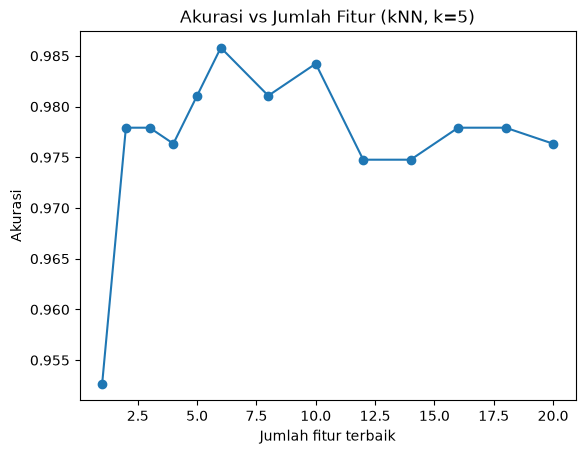

n =  1 -> akurasi 0.9527
n =  2 -> akurasi 0.9779
n =  3 -> akurasi 0.9779
n =  4 -> akurasi 0.9763
n =  5 -> akurasi 0.9811
n =  6 -> akurasi 0.9858
n =  8 -> akurasi 0.9811
n = 10 -> akurasi 0.9842
n = 12 -> akurasi 0.9748
n = 14 -> akurasi 0.9748
n = 16 -> akurasi 0.9779
n = 18 -> akurasi 0.9779
n = 20 -> akurasi 0.9763


In [7]:
def akurasi_subset(kolom, k=5):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled[kolom], y_train)
    return model.score(X_test_scaled[kolom], y_test)

kandidat = list(ranking.index)
daftar_n = [1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20]
akurasi_n = [akurasi_subset(kandidat[:n]) for n in daftar_n]

plt.plot(daftar_n, akurasi_n, marker='o')
plt.title('Akurasi vs Jumlah Fitur (kNN, k=5)')
plt.xlabel('Jumlah fitur terbaik')
plt.ylabel('Akurasi')
plt.show()

for n, a in zip(daftar_n, akurasi_n):
    print(f'n = {n:2d} -> akurasi {a:.4f}')

## 8. Menentukan Fitur Terbaik

Berdasarkan grafik, dipilih jumlah fitur dengan akurasi tertinggi. Fitur-fitur yang terpilih kemudian dicetak.

In [8]:
n_terbaik = daftar_n[int(np.argmax(akurasi_n))]
fitur_terbaik = kandidat[:n_terbaik]

print(f'Jumlah fitur terbaik: {n_terbaik}')
print('Fitur terpilih:')
print(fitur_terbaik)
print(f'Akurasi: {max(akurasi_n):.4f}')

Jumlah fitur terbaik: 6
Fitur terpilih:
['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm']
Akurasi: 0.9858


## 9. Menentukan Nilai k Terbaik

Menggunakan fitur terpilih, akurasi latih dan uji dihitung untuk nilai k dari 1 sampai 30 untuk menentukan k yang paling baik.

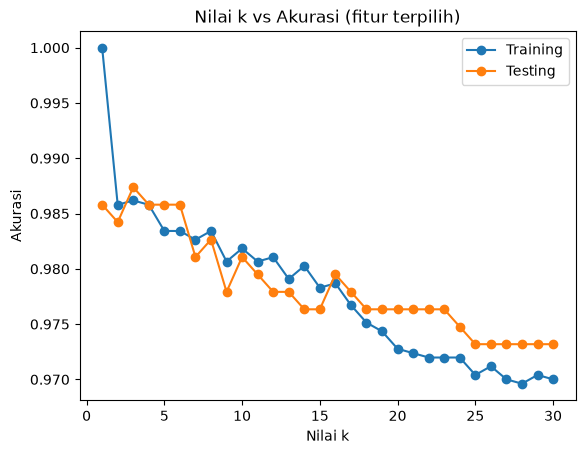

Nilai k terbaik: 3
Akurasi uji terbaik: 0.9874


In [9]:
daftar_k = range(1, 31)
akurasi_latih = []
akurasi_uji = []

for k in daftar_k:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled[fitur_terbaik], y_train)
    akurasi_latih.append(model.score(X_train_scaled[fitur_terbaik], y_train))
    akurasi_uji.append(model.score(X_test_scaled[fitur_terbaik], y_test))

plt.plot(daftar_k, akurasi_latih, marker='o', label='Training')
plt.plot(daftar_k, akurasi_uji, marker='o', label='Testing')
plt.title('Nilai k vs Akurasi (fitur terpilih)')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.legend()
plt.show()

k_terbaik = list(daftar_k)[int(np.argmax(akurasi_uji))]
print(f'Nilai k terbaik: {k_terbaik}')
print(f'Akurasi uji terbaik: {max(akurasi_uji):.4f}')

## 10. Model Akhir dan Evaluasi

Model kNN akhir dilatih dengan jumlah fitur dan nilai k terbaik, kemudian dievaluasi menggunakan akurasi, confusion matrix, dan laporan klasifikasi.

In [10]:
model_akhir = KNeighborsClassifier(n_neighbors=k_terbaik)
model_akhir.fit(X_train_scaled[fitur_terbaik], y_train)
y_pred = model_akhir.predict(X_test_scaled[fitur_terbaik])

print('Akurasi:', accuracy_score(y_test, y_pred))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('Laporan Klasifikasi:\n', classification_report(y_test, y_pred, target_names=['female', 'male']))

Akurasi: 0.9873817034700315
Confusion Matrix:
 [[313   4]
 [  4 313]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      female       0.99      0.99      0.99       317
        male       0.99      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



## 11. Kesimpulan Tugas 1

Tulis ringkasan fitur yang paling optimal, nilai k terbaik, serta akurasi akhir model beserta analisis singkatnya. Fitur akustik seperti `meanfun`, `IQR`, dan `Q25` umumnya paling membedakan suara pria dan wanita karena berkaitan dengan tinggi-rendahnya nada dasar suara.